# 00 · nextbrain-utils: overview

This series explains the `nextbrain-utils` package (author: Yael Balbastre,
with a contribution from Laura Boettcher): what each module does, how it works
inside, and the problems I found while reading it.

**What NextBrain is.** NextBrain is a probabilistic histological atlas of the
whole human brain (Casamitjana et al., *Nature* 2025). Its segmentation tool
labels a scan into more than 300 regions. The subcortical labels follow the
**Allen Human Brain Atlas ontology**. The cortex uses FreeSurfer's
**Desikan-Killiany (DK)** parcellation.

**What this package does.** It translates NextBrain label maps into other label
schemes and produces the lookup tables (LUTs) needed to view them:

```
seg.left.nii.gz ─┐
                 ├─ combine ─► seg.combined.nii.gz  +  seg.sides.nii.gz (1=L, 2=R)
seg.right.nii.gz ┘                 │                         │
                                   ├─ allen ──► seg.allen ─► simplify ─► seg.simple
                                   │                                  (collapse ontology subtrees)
                                   ├─ aseg ───────────────────────────┐
                                   ├─ supersynth ─────────────────────┤ (use the sides mask
                                   └─ laura ──────────────────────────┘  to lateralise labels)
lut ─► FreeSurfer-style LUT .txt files (for Freeview)
```

## Module map

| Module | Public function(s) | Role | Notebook |
|---|---|---|---|
| `io.py` | `load_lut`, `LUT`, `load_yaml`, `load_json`, `load_ontology` | Read LUTs, YAML mappings and the Allen JSON tree | 01 |
| `lut.py` | `allen_lut`, `make_allen_lut`, `make_dk_lut` | Build a FreeSurfer LUT from the Allen ontology | 02 |
| `combine_hemis.py` | `combine_hemis` | Merge the left and right hemisphere volumes into one grid | 03 |
| `to_allen.py` | `to_allen`, `get_nextbrain2allen_map`, `normalize_name`, `CortexOntology` | NextBrain → Allen IDs (matched by name) | 04 |
| `simplify.py` | `simplify`, `get_allen2simple_map` | Collapse Allen subtrees onto their parent node | 05 |
| `to_aseg.py` | `to_aseg`, `get_nextbrain2aseg_map` | NextBrain → ASeg+AParc (driven by YAML) | 06 |
| `to_supersynth.py` | `to_supersynth`, `get_nextbrain2supersynth_map` | NextBrain → SuperSynth (driven by YAML) | 06 |
| `to_laura.py` | `to_laura`, `get_nextbrain2laura_map` | NextBrain → "Laura" coarse scheme (driven by YAML) | 06 |
| `cli.py` | `main` | `nextbrain-utils <subcommand>` entry point | 07 |

In [2]:
import sys, os
from pathlib import Path
sys.path.insert(0, ".")          # nb_helpers.py lives next to the notebooks
WORK = Path("_work/00"); WORK.mkdir(parents=True, exist_ok=True)   # scratch outputs of this notebook

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
import nb_helpers as H
pd.set_option("display.max_rows", 60, "display.max_colwidth", 70)

In [3]:
import nextbrain_utils
PKG = Path(nextbrain_utils.__file__).parent
print("package:", PKG)
for p in sorted(PKG.rglob("*")):
    if p.is_file() and "__pycache__" not in p.parts:
        n = sum(1 for _ in open(p, errors="ignore"))
        print(f"{str(p.relative_to(PKG)):45s} {n:6d} lines")

package: /home/agustin/phd/synthseg_nextbrain/project/dev/wp1/allen_ontology/nextbrain-utils/nextbrain_utils
__init__.py                                        1 lines
__main__,py                                        3 lines
cli.py                                           575 lines
combine_hemis.py                                 150 lines
io.py                                            137 lines
lut/ASegLUT.txt                                  106 lines
lut/AllenBrainOntology.json                    24547 lines
lut/AllenBrainOntologyDev.json                 44009 lines
lut/FreeSurferColorLUT.txt                      2022 lines
lut/LauraLUT.txt                                  30 lines
lut/NextBrainLUT.txt                             883 lines
lut/NextBrainLabels.yaml                         336 lines
lut/NextBrainToASeg.yaml                         367 lines
lut/NextBrainToLaura.yaml                        263 lines
lut/NextBrainToSuperSynth.yaml                   364 lines
lut/Su

## The core idea: a "linear label map"

All converters (`to_allen`, `to_aseg`, `to_supersynth`, `to_laura`, `simplify`)
work the same way:

1. Build a 1-D integer array `mapping` such that `mapping[old_id] == new_id`.
   It usually starts as the identity, `np.arange(max_id + 1)`. **Any label
   the mapping does not mention therefore passes through unchanged.** Keep this
   in mind; it matters several times below.
2. Apply it to the whole volume with one NumPy fancy-indexing call:
   `new = mapping[seg]`.

This is O(#voxels), needs no loops, and is the same as a "LUT remap" in image
processing. A toy example:

In [4]:
seg = np.array([[0, 7, 7],
                [79, 79, 2028],
                [218, 5, 2028]])          # 5 is "not mentioned" in the mapping

mapping = np.arange(2036)                # identity
mapping[7]    = 2      # white matter -> Left-Cerebral-White-Matter
mapping[79]   = 12     # putamen      -> Left-Putamen
mapping[218]  = 10     # thalamus     -> Left-Thalamus
mapping[2028] = 1028   # ctx-rh-superiorfrontal -> ctx-lh-superiorfrontal

print(mapping[seg])    # 5 is unchanged: the mapping started as the identity

[[   0    2    2]
 [  12   12 1028]
 [  10    5 1028]]


## Shared conventions of the converter functions

* **Input**: a path, a `nibabel` `SpatialImage` or (according to the
  docstrings) an array. *In practice array inputs crash*, because the code
  calls `nb.Nifti1Image(data)` without an affine (shown in notebook 04).
* **`save`**: `False` (default) keeps the result in memory only. `True` writes
  next to the input with an automatic suffix (`.gyral`, `.simplified`,
  `.aseg+aparc`, ...). A path writes to that path.
* **Return value**: a `SpatialImage` that keeps the input's header (the affine
  is taken from the header because `None` is passed as the affine).

## The test data used in this series

There is no real NextBrain segmentation in this folder. So `nb_helpers.make_phantom_hemi()`
builds a **synthetic hemisphere**: ellipsoids that carry **real NextBrain label
IDs** (white matter 7, putamen 79, thalamus 218, DK cortex 2024/2028/2030/...,
and so on). It is anatomically crude, but it runs every code path with real IDs.

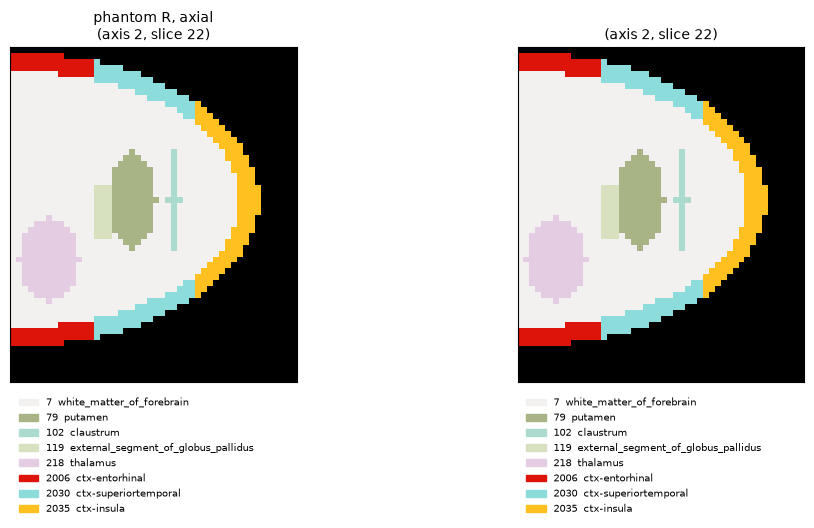

In [6]:
from nextbrain_utils.io import load_lut
nxb_lut = load_lut()
right = H.make_phantom_hemi("R")
H.show_seg([right, right], nxb_lut, axis=2, index=22, titles=["phantom R, axial", ""], legend=True)

## Issues found while studying the code

Each one is demonstrated in the notebook listed in the last column.

| # | Where | Problem | Effect | NB |
|---|---|---|---|---|
| 1 | `to_allen.get_nextbrain2allen_map` | Strips 7 characters (`"ctx-rh-"`) from cortical names, but since commit `310dbf2 Align LUT` the LUT names them `ctx-<name>` | **`to_allen` with `gyr` (the default) or `dev` raises `KeyError: 'nown'`**. Only `-c dk` works | 04 |
| 2 | `lut.make_dk_lut` | Only keeps names starting with `ctx-rh-`, for the same reason | `lut -l allen+dk` **silently writes no DK labels** | 02 |
| 3 | `to_laura.get_nextbrain2laura_map` | Sets IDs ≥1000 to 3 and then IDs ≥2000 to 103, but the second step finds nothing because those IDs are already 3 | All cortex becomes `Left-Cerebral-Cortex` (3), **even in the right hemisphere** | 06 |
| 4 | all converters | `nb.Nifti1Image(data)` is called without an affine | Array inputs (documented as allowed) raise `TypeError` | 04 |
| 5 | `to_aseg/supersynth/laura` | `_is_side(side)` calls `side.upper()` | A side mask works only as a *file path*, not as an image or array | 06 |
| 6 | `to_allen` | 29 subcortical NextBrain labels have no Allen name match and keep their NextBrain ID | With `-s16`, 8 of them collide with remapped Allen IDs in [1,199] ∪ [600,999] | 04 |
| 7 | `simplify` | Allocates an `int32` array of length 2²⁹ | Uses about **2 GiB of RAM** per call | 05 |
| 8 | `__main__,py` | Comma instead of a dot in the file name | `python -m nextbrain_utils` fails | 07 |
| 9 | `to_laura` (`save=True`) | Uses the suffix `.aseg+aparc` (copy-paste) | Would overwrite a `to_aseg` output with the same input | 06 |
| 10 | `io.LUT.colors` / `label2color` / `name2color` | Cast a structured array straight to `uint8` | `TypeError` on NumPy 2.x | 01 |
| 11 | s16 remap (`to_allen`, `lut`, `simplify`) | The Allen prefix `267498xxx` (6 nodes, area 7ip) is not remapped | NextBrain 594 `area_7ip__rostral_part` becomes 267498983, which **silently overflows to −18969** in `int16` | 02, 04 |
| 12 | `to_allen._fscortex_to_allen_gyral` | Target `"... (Heschl's gyrus)"` has a capital H, but Allen names are lowercased before comparing | In `gyr` mode, `ctx-transversetemporal` (2034) is **never mapped** and stays 2034 | 04 |
| 13 | `to_supersynth(claustrum=True)` / `supersynth -c` | The SuperSynth LUT has no `Left/Right-Claustrum` | `IndexError` | 06 |

Next: **01 · Lookup tables and I/O**.